# Análisis del barrido HTTP por segmentos (E1)

Primer barrido completo del país leyendo las páginas públicas de FincaRaíz por segmentos
(`src/scraper_http.py`). Preguntas:

1. **¿Cuánto cubre?** Frente al total que declara el portal.
2. **¿Qué tan buenos son los campos?** Cuáles vienen vacíos, son constantes o no aportan.
3. **¿Qué hay en `json_crudo`?** Es el 79% del archivo: ¿vale la pena guardarlo?
4. **¿Qué ve el barrido que el scraper actual no ve, y al revés?**
5. **¿Cómo guardarlo sin agotar el plan gratuito de R2?**

Datos: `data/r2/raw/venta_http/fecha=…/` (se bajan con `python -m src.almacen traer raw/venta_http/`
o desde el panel de Cloudflare).

In [1]:
import io, json, sys, collections
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

BASE = ROOT / "data" / "r2" / "raw" / "venta_http"
FECHA = sorted(p.name.split("=")[1] for p in BASE.glob("fecha=*"))[-1]   # el barrido más reciente
CARPETA = BASE / f"fecha={FECHA}"
ARCHIVO = CARPETA / "scrape.parquet"

AZUL, GRIS, TINTA, TINTA2, REJILLA = "#2a78d6", "#a3a29b", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "font.size": 10.5,
})
pd.set_option("display.max_colwidth", 70)
print("Barrido del", FECHA, "·", f"{ARCHIVO.stat().st_size / 1e6:.0f} MB")

Barrido del 2026-10-25 · 270 MB


## 1. Cobertura

El reporte que deja el propio barrido: avisos únicos frente al total que declara el portal.

In [2]:
reporte = json.loads((CARPETA / "reporte.json").read_text())
pd.Series(reporte, name="valor").to_frame()

,valor
fecha,2026-10-25
segmentos,135
paginas,8613
errores_pagina,0
filas_leidas,179118
avisos_unicos,169837
total_nacional_declarado,182434
cobertura,0.931
segmentos_bajo_90pct,[venta/norte-de-santander]


In [3]:
COLS = [c for c in pq.ParquetFile(ARCHIVO).schema.names if c != "json_crudo"]
df = pd.read_parquet(ARCHIVO, columns=COLS)
por_segmento = df["segmento"].value_counts()
print(f"{len(df):,} avisos únicos · {df['segmento'].nunique()} segmentos · "
      f"cobertura {reporte['cobertura']:.1%} del total nacional declarado ({reporte['total_nacional_declarado']:,})")
print("Segmentos bajo el 90% de lo declarado:", reporte["segmentos_bajo_90pct"])

169,837 avisos únicos · 133 segmentos · cobertura 93.1% del total nacional declarado (182,434)
Segmentos bajo el 90% de lo declarado: ['venta/norte-de-santander']


## 2. ¿Qué pesa en el archivo?

Peso comprimido de cada columna (metadatos del parquet).

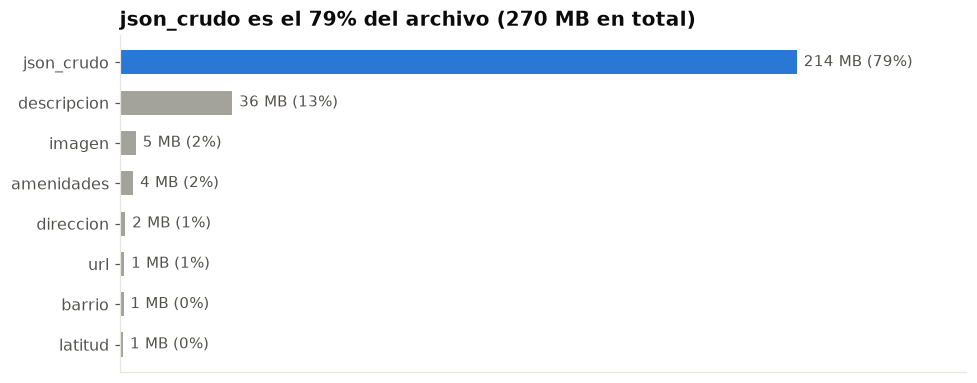

In [4]:
md_ = pq.ParquetFile(ARCHIVO).metadata
peso = collections.Counter()
for g in range(md_.num_row_groups):
    rg = md_.row_group(g)
    for c in range(rg.num_columns):
        peso[rg.column(c).path_in_schema] += rg.column(c).total_compressed_size
peso = pd.Series(peso).sort_values(ascending=False) / 1e6
top = peso.head(8)[::-1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(top.index, top.values, color=[AZUL if i == "json_crudo" else GRIS for i in top.index], height=0.6)
for y, v in enumerate(top.values):
    ax.text(v + peso.max() * 0.01, y, f"{v:.0f} MB ({v / peso.sum():.0%})", va="center", fontsize=9.5, color=TINTA2)
ax.set_xlim(0, peso.max() * 1.25); ax.xaxis.set_visible(False); ax.grid(False)
ax.set_title(f"json_crudo es el {peso['json_crudo'] / peso.sum():.0%} del archivo ({peso.sum():.0f} MB en total)")
fig.tight_layout(); plt.show()

## 3. Calidad de cada campo

**Vacío** = nulo, texto vacío o lista vacía. **Ceros** se muestran aparte, porque en algunos campos
un 0 es un dato real (piso 0) y en otros significa "no informado" (administración 0).

In [5]:
def perfil(s: pd.Series) -> dict:
    texto = s.astype(str).str.strip()
    vacio = s.isna() | texto.isin(["", "[]", "{}", "None", "nan"])
    cero = pd.to_numeric(s, errors="coerce").eq(0)
    vc = s.dropna().astype(str).value_counts()
    return {"vacío": vacio.mean(), "ceros": cero.mean(), "distintos": s.nunique(dropna=True),
            "valor más común": f"{vc.index[0][:40]} ({vc.iloc[0] / len(s):.0%})" if len(vc) else ""}

calidad = pd.DataFrame({c: perfil(df[c]) for c in COLS}).T
calidad["peso MB"] = peso.reindex(calidad.index).round(1)

# Recomendación: reglas + criterio
DESCARTAR = {
    "operacion": "constante: siempre 'Venta'",
    "precio_oculto": "constante: siempre falso",
    "vendido": "constante: siempre falso",
    "activo": "casi constante: todos los vistos están activos",
    "variacion_precio": "siempre vacío",
    "descuento": "siempre vacío",
    "duplicados": "siempre 0",
    "fecha_recoleccion": "constante en cada archivo: la fecha ya va en la ruta",
    "pagina": "dato de depuración del barrido",
    "imagen": "URL de la foto; no se usa en el análisis",
    "url": "se reconstruye desde id + título; se puede conservar si se quiere el enlace directo",
}
REVISAR = {
    "codigo_anunciante": "código interno del anunciante; útil para detectar el mismo inmueble en varias publicaciones",
    "amenidades": "pesa, pero útil para comparables (E4)",
    "descripcion": "la más pesada útil: filtros por texto. Guardarla solo cuando el aviso es nuevo o cambia",
    "titulo": "casi redundante con tipo + ubicación",
    "direccion": "útil a veces; 7% vacía y muchas son genéricas",
    "segmento": "útil para auditar la cobertura",
}
calidad["recomendación"] = ["descartar · " + DESCARTAR[c] if c in DESCARTAR else
                            "revisar · " + REVISAR[c] if c in REVISAR else "conservar" for c in calidad.index]
(calidad.sort_values("peso MB", ascending=False)
 .style.format({"vacío": "{:.0%}", "ceros": "{:.0%}", "distintos": "{:,.0f}", "peso MB": "{:.1f}"}))

,vacío,ceros,distintos,valor más común,peso MB,recomendación
descripcion,0%,0%,"166,623",Encuentra el inmueble ideal para vivir o (0%),35.5,revisar · la más pesada útil: filtros por texto. Guardarla solo cuando el aviso es nuevo o cambia
imagen,0%,0%,"169,505",https://cdn2.infocasas.com.uy/repo/img/6 (0%),5.1,descartar · URL de la foto; no se usa en el análisis
amenidades,11%,0%,"126,246",Cocina Integral (0%),4.3,"revisar · pesa, pero útil para comparables (E4)"
direccion,7%,0%,"120,270",- (2%),1.8,revisar · útil a veces; 7% vacía y muchas son genéricas
url,0%,0%,"169,837",https://www.fincaraiz.com.co/apartamento (0%),1.5,descartar · se reconstruye desde id + título; se puede conservar si se quiere el enlace directo
barrio,4%,0%,"53,185",Centro (1%),1.2,conservar
latitud,0%,0%,"107,434",6.1490188 (0%),1.1,conservar
longitud,0%,0%,"106,181",-75.5676977 (0%),1.1,conservar
codigo_anunciante,16%,0%,"131,990",(1%),0.9,revisar · código interno del anunciante; útil para detectar el mismo inmueble en varias publicaciones
id_inmueble,0%,0%,"169,837",194453763 (0%),0.8,conservar


## 4. ¿Qué hay dentro de `json_crudo`?

Muestra de 20.000 avisos: peso de cada campo del JSON original, cuántos avisos lo traen lleno y si
ya lo aplanamos.

In [6]:
js = pd.read_parquet(ARCHIVO, columns=["json_crudo"])["json_crudo"].sample(20_000, random_state=1)
tam, lleno, distintos = collections.Counter(), collections.Counter(), collections.defaultdict(set)
for t in js:
    for k, v in json.loads(t).items():
        tam[k] += len(json.dumps(v, ensure_ascii=False))
        if v not in (None, "", 0, False, [], {}):
            lleno[k] += 1
        if len(distintos[k]) < 50:
            distintos[k].add(json.dumps(v, ensure_ascii=False)[:60])
APLANADOS = {"images": "imagen (solo la principal)", "locations": "departamento…barrio, latitud/longitud",
             "facilities": "amenidades", "technicalSheet": "estado, estrato, piso…", "description": "descripcion",
             "owner": "anunciante, anunciante_id", "price": "precio, moneda", "img": "imagen",
             "commonExpenses": "administracion", "link": "url", "title": "titulo", "address": "direccion",
             "created_at": "fecha_publicacion", "updated_at": "fecha_actualizacion", "tag": "etiquetas",
             "code2": "codigo_anunciante", "latitude": "latitud", "longitude": "longitud"}
tot = sum(tam.values())
interno = pd.DataFrame({"peso": {k: v / tot for k, v in tam.items()},
                        "lleno": {k: lleno[k] / len(js) for k in tam},
                        "distintos (máx. 50)": {k: len(distintos[k]) for k in tam}})
interno["ya aplanado en"] = interno.index.map(lambda k: APLANADOS.get(k, ""))
print(f"{len(tam)} campos en el JSON original")
interno.sort_values("peso", ascending=False).head(25).style.format({"peso": "{:.1%}", "lleno": "{:.0%}"})

128 campos en el JSON original


,peso,lleno,distintos (máx. 50),ya aplanado en
images,29.6%,99%,50,imagen (solo la principal)
locations,13.5%,100%,50,"departamento…barrio, latitud/longitud"
facilities,10.5%,89%,50,amenidades
socialMediaLinks,10.0%,100%,2,
technicalSheet,9.3%,100%,19,"estado, estrato, piso…"
description,8.0%,100%,50,descripcion
owner,6.5%,100%,50,"anunciante, anunciante_id"
price,1.4%,100%,50,"precio, moneda"
img,1.2%,100%,50,imagen
turbo_product,1.0%,100%,8,


In [7]:
# Campos NO aplanados que traen información (llenos en ≥ 5% y con variedad)
utiles = interno[(interno["ya aplanado en"] == "") & (interno["lleno"] >= 0.05) & (interno["distintos (máx. 50)"] > 2)]
utiles.sort_values("lleno", ascending=False).style.format({"peso": "{:.1%}", "lleno": "{:.0%}"})

,peso,lleno,distintos (máx. 50),ya aplanado en
id,0.1%,100%,50,
typeID,0.0%,100%,14,
code,0.1%,100%,50,
description_count,0.0%,100%,50,
project_group_md5,0.2%,100%,50,
property_type,0.3%,100%,28,
property_type_id,0.0%,100%,14,
turbo_product,1.0%,100%,8,
legacy_propID,0.1%,100%,50,
price_admin_usd,0.1%,100%,50,


## 5. Barrido nuevo frente al scraper actual

`master` = todo lo que el scraper actual vio alguna vez · `activos` = el dataset de la app (lo que hoy
damos por publicado).

In [8]:
master = pd.read_parquet(ROOT / "data" / "master" / "listings.parquet", columns=["id_inmueble", "last_seen"])
master["id_inmueble"] = master["id_inmueble"].astype(str)
activos = pd.read_parquet(ROOT / "data" / "app" / "housing_clean.parquet", columns=["id_inmueble"])["id_inmueble"].astype(str)
ib, im, ia = set(df["id_inmueble"]), set(master["id_inmueble"]), set(activos)
cruce = pd.Series({
    "avisos en el barrido": len(ib),
    "también en el master": len(ib & im),
    "solo en el barrido (el scraper actual nunca los vio)": len(ib - im),
    "'activos' del master que el barrido no vio": len(ia - ib),
}, name="avisos").to_frame()
cruce["% del barrido"] = cruce["avisos"] / len(ib)
cruce.style.format({"avisos": "{:,.0f}", "% del barrido": "{:.0%}"})

,avisos,% del barrido
avisos en el barrido,"169,837",100%
también en el master,"88,513",52%
solo en el barrido (el scraper actual nunca los vio),"81,324",48%
'activos' del master que el barrido no vio,"50,539",30%


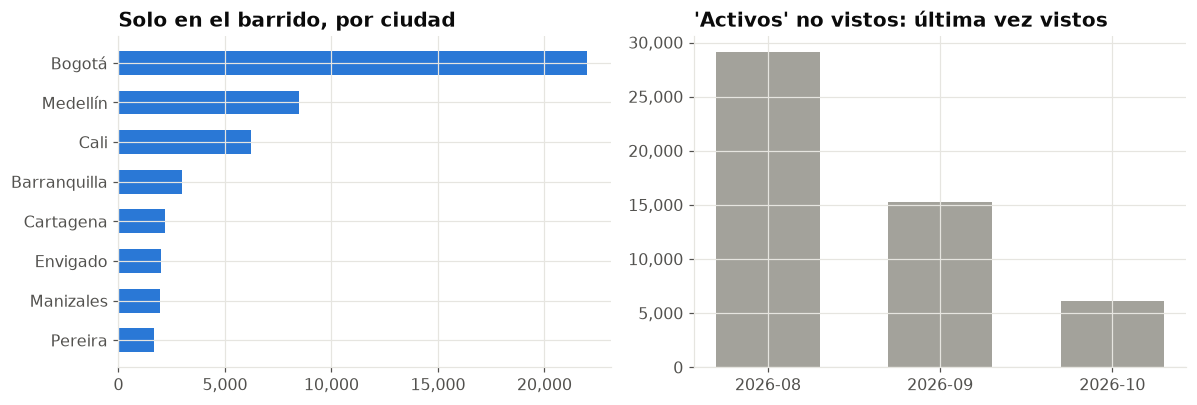

De los 'activos' que el barrido no vio, el 88% no se ve desde antes de octubre: lo más probable es que ya se hayan retirado.


In [9]:
solo_barrido = df[~df["id_inmueble"].isin(im)]
no_vistos = master[master["id_inmueble"].isin(ia - ib)]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
s = solo_barrido["ciudad"].value_counts().head(8)[::-1]
axs[0].barh(s.index, s.values, color=AZUL, height=0.6); axs[0].set_title("Solo en el barrido, por ciudad")
axs[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
m = pd.to_datetime(no_vistos["last_seen"]).dt.strftime("%Y-%m").value_counts().sort_index()
axs[1].bar(m.index, m.values, color=GRIS, width=0.6); axs[1].set_title("'Activos' no vistos: última vez vistos")
axs[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
fig.tight_layout(); plt.show()
print(f"De los 'activos' que el barrido no vio, el {(pd.to_datetime(no_vistos['last_seen']) < '2026-10-01').mean():.0%} "
      "no se ve desde antes de octubre: lo más probable es que ya se hayan retirado.")

## 6. ¿Desde cuándo están publicados los avisos?

`fecha_publicacion` es la fecha en que el portal dice que se publicó el aviso. Antes de esto solo
sabíamos que lo vimos por primera vez el 8 de agosto de 2026 (la siembra del master).

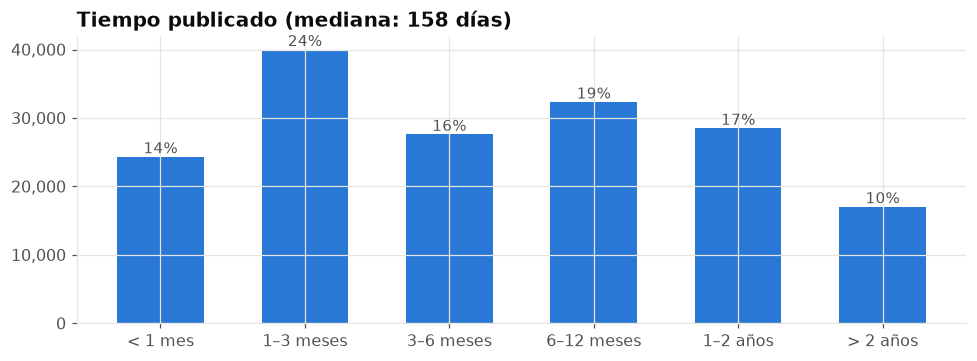

Publicados antes del 8-ago-2026: 65% · el más viejo: 2014-09-05


In [10]:
pub = pd.to_datetime(df["fecha_publicacion"], errors="coerce")
dias = (pd.Timestamp(FECHA) - pub).dt.days
tramos = pd.cut(dias, [-1, 30, 90, 180, 365, 730, 100_000],
                labels=["< 1 mes", "1–3 meses", "3–6 meses", "6–12 meses", "1–2 años", "> 2 años"])
t = tramos.value_counts().reindex(tramos.cat.categories)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(t.index.astype(str), t.values, color=AZUL, width=0.6)
for x, v in enumerate(t.values):
    ax.text(x, v, f"{v / t.sum():.0%}", ha="center", va="bottom", fontsize=9.5, color=TINTA2)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title(f"Tiempo publicado (mediana: {dias.median():.0f} días)")
fig.tight_layout(); plt.show()
print(f"Publicados antes del 8-ago-2026: {(pub < '2026-08-08').mean():.0%} · el más viejo: {pub.min():%Y-%m-%d}")

## 7. Señales de calidad de los datos

In [11]:
num = lambda c: pd.to_numeric(df[c], errors="coerce")
pm2 = num("precio") / num("m2").replace(0, np.nan)
fuera = ~(num("latitud").between(-4.3, 13.5) & num("longitud").between(-82, -66.8))
senales = pd.Series({
    "precio en dólares (moneda U$S)": (df["moneda"] == "U$S").sum(),
    "precio por m² menor a $500.000 (probable error)": (pm2 < 5e5).sum(),
    "precio por m² mayor a $50 M (probable error)": (pm2 > 5e7).sum(),
    "coordenadas fuera de Colombia": fuera.sum(),
    "administración = 0 (no informada)": num("administracion").eq(0).sum(),
    "m² construidos = 0": num("m2_construido").eq(0).sum(),
    "habitaciones = 0": num("habitaciones").eq(0).sum(),
    "proyectos o unidades de proyecto": (df["es_proyecto"].astype(str).eq("True") | df["es_unidad_proyecto"].astype(str).eq("True")).sum(),
}, name="avisos").to_frame()
senales["%"] = senales["avisos"] / len(df)
senales.style.format({"avisos": "{:,.0f}", "%": "{:.1%}"})

,avisos,%
precio en dólares (moneda U$S),8,0.0%
precio por m² menor a $500.000 (probable error),"10,791",6.4%
precio por m² mayor a $50 M (probable error),"1,854",1.1%
coordenadas fuera de Colombia,3,0.0%
administración = 0 (no informada),"80,761",47.6%
m² construidos = 0,"7,788",4.6%
habitaciones = 0,"27,907",16.4%
proyectos o unidades de proyecto,392,0.2%


## 8. Duplicados: el mismo inmueble con distintos ids

El campo `duplicados` del portal viene siempre en 0, así que se estima: mismo barrio, tipo, precio,
área y habitaciones con distinto id.

In [12]:
clave = ["ciudad", "barrio", "tipo", "precio", "m2", "habitaciones"]
d = df.dropna(subset=["barrio"])
grupos = d.groupby(clave)["id_inmueble"].transform("size")
dup = d[grupos > 1]
print(f"{len(dup):,} avisos ({len(dup) / len(df):.0%}) comparten barrio, tipo, precio, área y habitaciones "
      f"con otro aviso → {dup.groupby(clave).ngroups:,} grupos.")
print(f"En el {dup.groupby(clave)['anunciante_id'].nunique().gt(1).mean():.0%} de esos grupos los publican "
      "anunciantes distintos (el mismo inmueble con varias inmobiliarias).")
dup.sort_values(clave).head(6)[clave + ["anunciante", "fecha_publicacion"]]

10,324 avisos (6%) comparten barrio, tipo, precio, área y habitaciones con otro aviso → 4,638 grupos.
En el 66% de esos grupos los publican anunciantes distintos (el mismo inmueble con varias inmobiliarias).


,ciudad,barrio,tipo,precio,m2,habitaciones,anunciante,fecha_publicacion
136757,Anapoima,La chica,Casa,3.050000e+08,113.0,3.0,HOME PRO,2026-06-13
137764,Anapoima,La chica,Casa,3.050000e+08,113.0,3.0,HOME PRO,2026-03-04
135070,Anapoima,Providencia garcia,Casa,1.680000e+09,879.0,5.0,Redinmuebles,2026-09-10
135886,Anapoima,Providencia garcia,Casa,1.680000e+09,879.0,5.0,Qrador SAS,2026-08-11
162533,Anapoima,San jose,Finca,2.479000e+09,950.0,9.0,William ibañez,2026-02-26
163124,Anapoima,San jose,Finca,2.479000e+09,950.0,9.0,William ibañez,2024-01-26


## 9. ¿Cómo guardarlo sin agotar el plan gratuito?

Hoy el barrido guarda **una copia completa por día**. Pero de un día a otro casi todo es igual: solo
cambian los avisos nuevos, los que cambian de precio y los que desaparecen.

In [13]:
def mb(d):
    b = io.BytesIO(); d.to_parquet(b, index=False, compression="zstd"); return b.tell() / 1e6

completo = ARCHIVO.stat().st_size / 1e6
sin_json = mb(df)
recortado = mb(df.drop(columns=[c for c in list(DESCARTAR) + ["descripcion", "amenidades"] if c in df]))
presencia = mb(df[["id_inmueble", "precio", "fecha_actualizacion"]])
opciones = pd.DataFrame({
    "MB por barrido": [completo, sin_json, recortado, presencia],
}, index=["Hoy: completo con json_crudo", "Sin json_crudo", "Recortado (sin descartables, descripción ni amenidades)",
          "Solo presencia: id, precio, fecha de actualización"])
opciones["GB al mes (diario)"] = opciones["MB por barrido"] * 30 / 1000
opciones["meses hasta 10 GB"] = 9 / opciones["GB al mes (diario)"]
opciones.style.format({"MB por barrido": "{:.1f}", "GB al mes (diario)": "{:.2f}", "meses hasta 10 GB": "{:.1f}"})

,MB por barrido,GB al mes (diario),meses hasta 10 GB
Hoy: completo con json_crudo,270.3,8.11,1.1
Sin json_crudo,56.8,1.70,5.3
"Recortado (sin descartables, descripción ni amenidades)",10.3,0.31,29.0
"Solo presencia: id, precio, fecha de actualización",1.2,0.04,241.8


## 10. Qué dicen (y qué recomiendan) estos datos

Barrido del **25 de octubre de 2026**. Si se ejecuta con otro barrido, las cifras cambian.

**1. El barrido funciona y cubre mucho más que el scraper actual.**
- Cobertura del **93,1%** del total que declara el portal (169.837 de 182.434), en 8.613 páginas y
  **sin errores**. Solo Norte de Santander quedó bajo el 90%.
- **El 48% de los avisos (81.324) nunca lo vio el scraper actual**, incluso en ciudades que ya recorre
  (Bogotá, Medellín, Cali). Su tope de 50 páginas por URL deja fuera gran parte de la oferta.

**2. El inventario "activo" de hoy está inflado.** 50.539 avisos que el dataset activo da por
publicados no aparecieron en el barrido, y el 88% de ellos no se ve desde antes de octubre: casi
seguro **ya se retiraron**. Eso infla el mapa y mete en los comparables avisos que ya no existen.
Con el barrido diario, esas bajas se detectan solas (E2).

**3. Fecha de publicación real:** el 65% de los avisos se publicó antes de que empezáramos a
recolectar (el más viejo, en 2014). Ahora hay días en el mercado reales.

**4. Campos que se pueden descartar** (constantes, vacíos o de depuración): `operacion`,
`precio_oculto`, `vendido`, `activo`, `variacion_precio`, `descuento`, `duplicados`,
`fecha_recoleccion` (ya va en la ruta), `pagina` e `imagen`. `url` es opcional.

**5. `json_crudo` no vale lo que pesa:** es el **79% del archivo** y casi todo está ya aplanado o no
aporta. Las fotos (`images`) son el 30%, los enlaces a redes sociales (siempre iguales) el 10% y la
descripción repetida el 8%. Ningún campo sin aplanar trae información que hoy necesitemos. Si se
quiere una red de seguridad, basta guardarlo **solo para los avisos nuevos de cada día**.

**6. Ajustes de calidad para la limpieza:**
- **Administración = 0 en el 48%**: es "no informada", no "sin administración". Tratarla como vacía.
- **Habitaciones = 0 en el 16%**: lotes, locales, oficinas…
- **Precio por m² absurdo en ~7,5%**: errores de digitación del área o del precio. Hay que seguir filtrándolos.

**7. Duplicados:** el 6% de los avisos coincide con otro en barrio, tipo, precio, área y habitaciones,
y en dos de cada tres casos los publican inmobiliarias distintas: el mismo inmueble, varias veces.
Es la base para deduplicar (E4).

**8. Almacenamiento: guardar diferencias, no copias.** Una copia completa por día agota el plan
gratuito en **~1 mes**. Propuesta:

| Qué | Cuándo | Tamaño aprox. |
|---|---|---|
| **Presencia**: id, precio, fecha de actualización de todos los avisos vistos | Cada día | ~1,2 MB |
| **Filas completas** (con descripción y amenidades) solo de avisos **nuevos o con cambios** | Cada día | Pocos MB |
| **Foto completa recortada** (sin `json_crudo` ni descartables) | Una vez por semana | ~10–57 MB |

Con la presencia diaria se detectan bajas y cambios de precio; con las filas nuevas no se pierde
ningún dato, y el crecimiento queda muy por debajo de 1 GB al año.